<a href="https://colab.research.google.com/github/asrilyusufharahap/Portofolio-Asril/blob/main/CapstoneProject_Asril_Yusuf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
import os
import pandas as pd

# Helper function to find the file path in Drive
def find_file(name, path='/content/drive'):
    for root, dirs, files in os.walk(path):
        if name in files:
            return os.path.join(root, name)
    return None

# Find the path of DaftarSaham.csv
file_path = find_file('DaftarSaham.csv')

if file_path:
    print(f"File ditemukan di: {file_path}")
    # Load dataset daftar saham menggunakan file_path hasil pencarian
    daftarSaham = pd.read_csv(file_path)

    # Filter perusahaan Telkom Indonesia (Persero) Tbk
    telkom = daftarSaham[daftarSaham["Code"] == "TLKM"]
    print(telkom)
else:
    print("Error: 'DaftarSaham.csv' tidak dapat ditemukan di Google Drive Anda. Pastikan file telah diunggah dengan benar.")

File ditemukan di: /content/drive/MyDrive/Capstone Project Asril Yusuf Harahap/DaftarSaham.csv
     Code                            Name ListingDate        Shares  \
755  TLKM  Telkom Indonesia (Persero) Tbk  1995-11-14  9.906222e+10   

    ListingBoard           Sector  LastPrice     MarketCap  \
755        Utama  Infrastructures     3710.0  3.675208e+14   

       MinutesFirstAdded   MinutesLastUpdated     HourlyFirstAdded  \
755  2021-11-01 09:00:00  2023-01-06 15:59:00  2020-04-16 09:00:00   

       HourlyLastUpdated DailyFirstAdded DailyLastUpdated  
755  2023-01-06 15:00:00      2001-04-16       2023-01-06  


In [31]:
import os
import pandas as pd

# Helper function to find the file path in Drive
def find_file(name, path='/content/drive'):
    for root, dirs, files in os.walk(path):
        if name in files:
            return os.path.join(root, name)
    return None

# Mencari lokasi file TLKM.csv secara otomatis di Google Drive
real_file_path = find_file('TLKM.csv')

if real_file_path:
    print(f"File ditemukan di: {real_file_path}")
    df = pd.read_csv(real_file_path)
    print(df.head())
else:
    print("Error: 'TLKM.csv' tidak dapat ditemukan di Google Drive Anda. Pastikan file telah diunggah ke Drive.")

File ditemukan di: /content/drive/MyDrive/Capstone Project Asril Yusuf Harahap/TLKM.csv
    timestamp  open  low  high  close  volume
0  2001-04-16   835  825   835    825       0
1  2001-04-17   835  825   835    825       0
2  2001-04-18   835  825   835    825       0
3  2001-04-19   835  825   835    825       0
4  2001-04-20   835  825   835    825       0


In [32]:
df. info ()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5670 entries, 0 to 5669
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   timestamp  5670 non-null   object
 1   open       5670 non-null   int64 
 2   low        5670 non-null   int64 
 3   high       5670 non-null   int64 
 4   close      5670 non-null   int64 
 5   volume     5670 non-null   int64 
dtypes: int64(5), object(1)
memory usage: 265.9+ KB


In [33]:
print(df.describe())

              open          low         high        close        volume
count  5670.000000  5670.000000  5670.000000  5670.000000  5.670000e+03
mean   2309.216226  2282.485009  2334.262787  2307.410053  8.046911e+07
std    1205.960504  1194.510116  1219.191198  1207.427204  7.039650e+07
min     820.000000   810.000000   825.000000   825.000000  0.000000e+00
25%    1380.000000  1360.000000  1390.000000  1380.000000  3.407112e+07
50%    1950.000000  1920.000000  1970.000000  1950.000000  7.391250e+07
75%    3400.000000  3360.000000  3440.000000  3400.000000  1.106009e+08
max    4850.000000  4780.000000  4850.000000  4800.000000  8.080050e+08


In [34]:
print(df.isna().sum())

timestamp    0
open         0
low          0
high         0
close        0
volume       0
dtype: int64


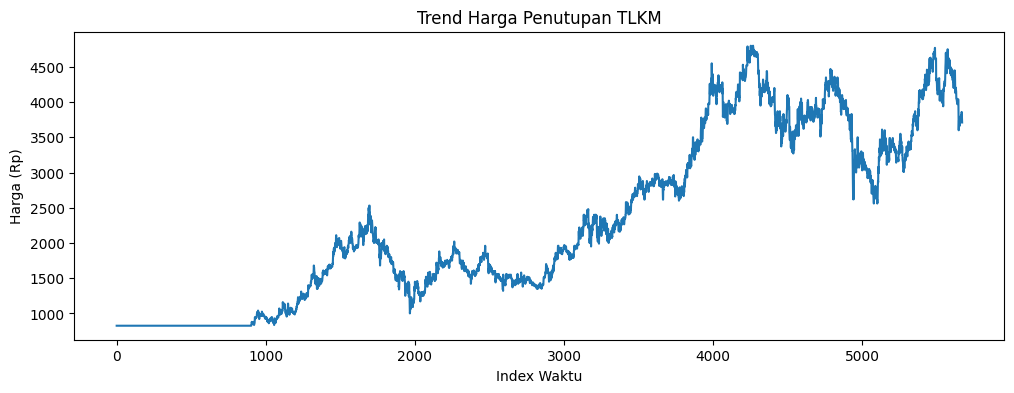

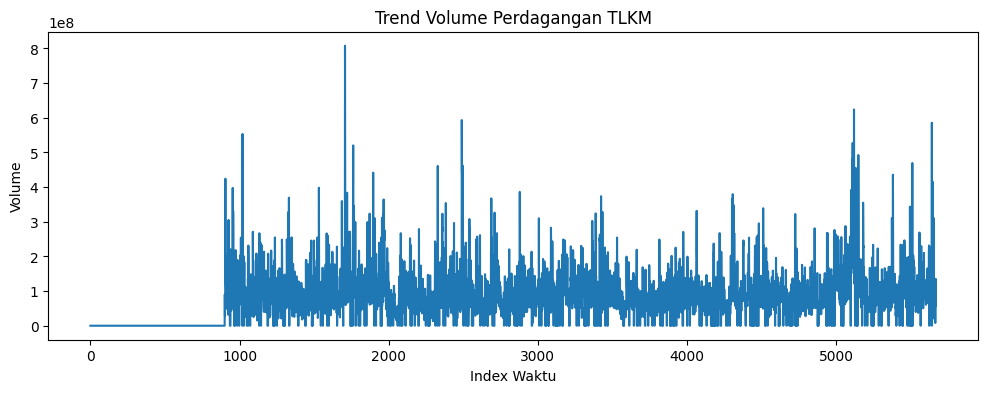

In [35]:
plt.figure(figsize=(12,4))
plt.plot(df['close'])
plt.title("Trend Harga Penutupan TLKM")
plt.xlabel("Index Waktu")
plt.ylabel("Harga (Rp)")
plt.show()

plt.figure(figsize=(12,4))
plt.plot(df['volume'])
plt.title("Trend Volume Perdagangan TLKM")
plt.xlabel("Index Waktu")
plt.ylabel("Volume")
plt.show()

In [36]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(by='timestamp')
df.reset_index(drop=True, inplace=True)

In [37]:
df.isna().sum()

# interpolasi (lebih cocok untuk time series harga)
df.fillna(method='ffill', inplace=True)
df.fillna(method='bfill', inplace=True)

/tmp/ipykernel_481/4085122017.py:4: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill', inplace=True)
/tmp/ipykernel_481/4085122017.py:5: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='bfill', inplace=True)


In [38]:
numeric_cols = ['open', 'high', 'low', 'close', 'volume']
df[numeric_cols] = df[numeric_cols].astype(float)

In [39]:
df.head()

,timestamp,open,low,high,close,volume
0,2001-04-16,835.0,825.0,835.0,825.0,0.0
1,2001-04-17,835.0,825.0,835.0,825.0,0.0
2,2001-04-18,835.0,825.0,835.0,825.0,0.0
3,2001-04-19,835.0,825.0,835.0,825.0,0.0
4,2001-04-20,835.0,825.0,835.0,825.0,0.0


In [40]:
print(df.shape)

(5670, 6)



Correlation matrix:
            open      high       low     close    volume
open    1.000000  0.999672  0.999710  0.999470  0.241240
high    0.999672  1.000000  0.999575  0.999725  0.248967
low     0.999710  0.999575  1.000000  0.999710  0.235419
close   0.999470  0.999725  0.999710  1.000000  0.243431
volume  0.241240  0.248967  0.235419  0.243431  1.000000


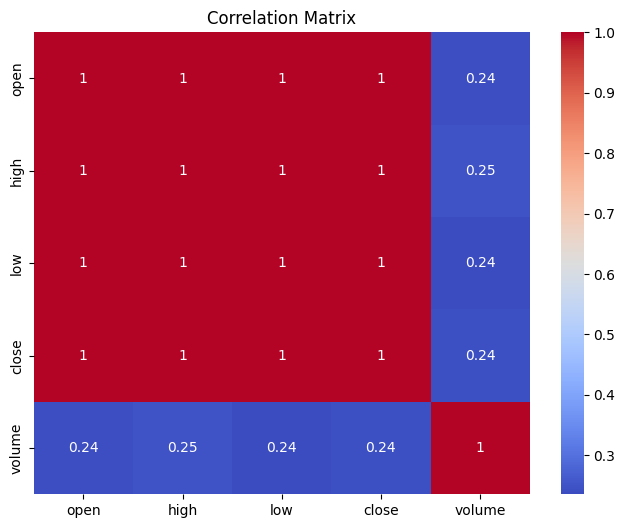

In [41]:
print('\nCorrelation matrix:')
print(df[['open','high','low','close','volume']].corr())

plt.figure(figsize=(8,6))
sns.heatmap(df[['open','high','low','close','volume']].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [42]:
data = df[['timestamp', 'close']].copy()
data.set_index('timestamp', inplace=True)

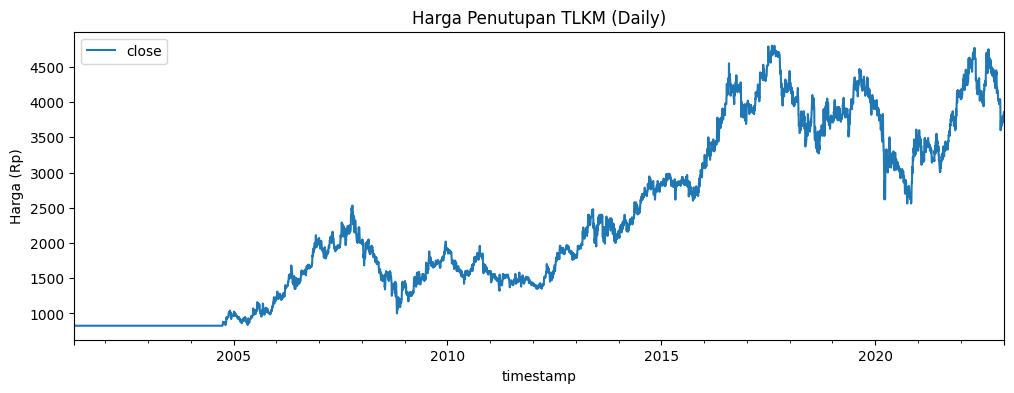

In [43]:
data.plot(figsize=(12,4), title='Harga Penutupan TLKM (Daily)')
plt.ylabel("Harga (Rp)")
plt.show()

In [44]:
train_size = int(len(data) * 0.8)
train = data.iloc[:train_size]
test = data.iloc[train_size:]
print("Train:", train.shape, " Test:", test.shape)


Train: (4536, 1)  Test: (1134, 1)


In [45]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(train['close'])
print("ADF Statistic:", result[0])
print("p-value:", result[1])

ADF Statistic: -0.6210238990501014
p-value: 0.866160373850916


/tmp/ipykernel_481/3593771165.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(train['close'])


In [46]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

baseline_pred = test['close'].shift(1).dropna()
baseline_true = test['close'][1:]

baseline_rmse = np.sqrt(mean_squared_error(baseline_true, baseline_pred))
baseline_mape = mean_absolute_percentage_error(baseline_true, baseline_pred)

print("Baseline RMSE:", baseline_rmse)
print("Baseline MAPE:", baseline_mape)


Baseline RMSE: 66.79195347153495
Baseline MAPE: 0.013165780698310045


In [47]:
from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(train['close'], order=(5,1,0))
arima_fit = arima_model.fit()

print(arima_fit.summary())


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                  close   No. Observations:                 4536
Model:                 ARIMA(5, 1, 0)   Log Likelihood              -22855.230
Date:                Mon, 16 Nov 2026   AIC                          45722.461
Time:                        16:35:44   BIC                          45760.978
Sample:                    04-16-2001   HQIC                         45736.027
                         - 09-03-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0372      0.009     -4.340      0.000      -0.054      -0.020
ar.L2         -0.0930      0.010     -9.052      0.000      -0.113      -0.073
ar.L3         -0.0709      0.010     -7.267      0.0

In [48]:
arima_pred = arima_fit.forecast(steps=len(test))


In [49]:
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
import numpy as np

arima_rmse = np.sqrt(mean_squared_error(test['close'], arima_pred))
arima_mape = mean_absolute_percentage_error(test['close'], arima_pred)

print("ARIMA RMSE:", arima_rmse)
print("ARIMA MAPE:", arima_mape)


ARIMA RMSE: 553.1011796029712
ARIMA MAPE: 0.12256081727171636


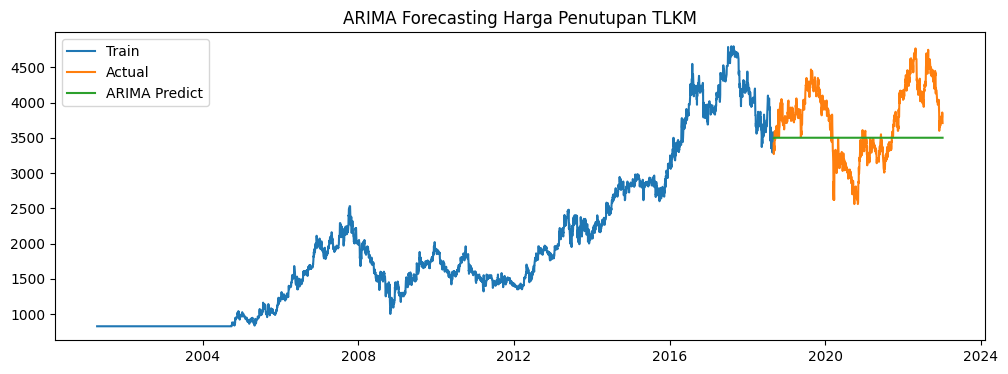

In [50]:
plt.figure(figsize=(12,4))
plt.plot(train.index, train['close'], label='Train')
plt.plot(test.index, test['close'], label='Actual')
plt.plot(test.index, arima_pred, label='ARIMA Predict')
plt.title("ARIMA Forecasting Harga Penutupan TLKM")
plt.legend()
plt.show()


In [51]:
df_prophet = data.reset_index().rename(columns={'timestamp':'ds', 'close':'y'})
train_p = df_prophet.iloc[:train_size]
test_p = df_prophet.iloc[train_size:]


In [52]:
from prophet import Prophet

prophet_model = Prophet()
prophet_model.fit(train_p)


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [53]:
future = prophet_model.make_future_dataframe(periods=len(test_p))
forecast = prophet_model.predict(future)

prophet_pred = forecast['yhat'].iloc[-len(test_p):].values


In [54]:
prophet_rmse = np.sqrt(mean_squared_error(test_p['y'], prophet_pred))
prophet_mape = mean_absolute_percentage_error(test_p['y'], prophet_pred)

print("Prophet RMSE:", prophet_rmse)
print("Prophet MAPE:", prophet_mape)


Prophet RMSE: 1497.8103367863216
Prophet MAPE: 0.39436884146833834


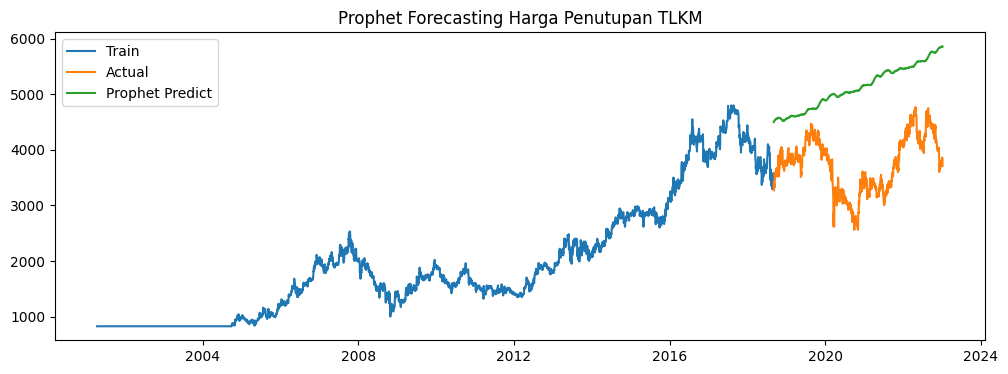

In [55]:
plt.figure(figsize=(12,4))
plt.plot(train.index, train['close'], label='Train')
plt.plot(test.index, test['close'], label='Actual')
plt.plot(test.index, prophet_pred, label='Prophet Predict')
plt.title("Prophet Forecasting Harga Penutupan TLKM")
plt.legend()
plt.show()


In [56]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)


In [57]:
import numpy as np

def create_sequences(dataset, window=60):
    X, y = [], []
    for i in range(window, len(dataset)):
        X.append(dataset[i-window:i, 0])
        y.append(dataset[i, 0])
    return np.array(X), np.array(y)

X_all, y_all = create_sequences(scaled_data)


In [58]:
X_train = X_all[:train_size]
y_train = y_all[:train_size]
X_test = X_all[train_size:]
y_test = y_all[train_size:]


In [59]:
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)


In [60]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

lstm_model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(X_train.shape[1],1)),
    Dropout(0.2),
    LSTM(50),
    Dense(1)
])

lstm_model.compile(loss='mse', optimizer='adam')
lstm_model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

In [61]:
history = lstm_model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)


Epoch 1/30
128/128 ━━━━━━━━━━━━━━━━━━━━ 15s 64ms/step - loss: 0.0040 - val_loss: 0.0012
Epoch 2/30
128/128 ━━━━━━━━━━━━━━━━━━━━ 10s 78ms/step - loss: 3.8683e-04 - val_loss: 0.0012
Epoch 3/30
128/128 ━━━━━━━━━━━━━━━━━━━━ 9s 70ms/step - loss: 3.6823e-04 - val_loss: 0.0013
Epoch 4/30
128/128 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - loss: 3.4966e-04 - val_loss: 0.0011
Epoch 5/30
128/128 ━━━━━━━━━━━━━━━━━━━━ 12s 77ms/step - loss: 3.4740e-04 - val_loss: 0.0013
Epoch 6/30
128/128 ━━━━━━━━━━━━━━━━━━━━ 9s 71ms/step - loss: 3.2068e-04 - val_loss: 9.6472e-04
Epoch 7/30
128/128 ━━━━━━━━━━━━━━━━━━━━ 9s 72ms/step - loss: 3.2212e-04 - val_loss: 0.0014
Epoch 8/30
128/128 ━━━━━━━━━━━━━━━━━━━━ 11s 78ms/step - loss: 3.1883e-04 - val_loss: 0.0012
Epoch 9/30
128/128 ━━━━━━━━━━━━━━━━━━━━ 8s 62ms/step - loss: 2.8803e-04 - val_loss: 0.0011
Epoch 10/30
128/128 ━━━━━━━━━━━━━━━━━━━━ 10s 78ms/step - loss: 2.8234e-04 - val_loss: 0.0012
Epoch 11/30
128/128 ━━━━━━━━━━━━━━━━━━━━ 9s 71ms/step - loss: 2.8915e-04 - val_loss:

In [62]:
lstm_pred_scaled = lstm_model.predict(X_test)
lstm_pred = scaler.inverse_transform(lstm_pred_scaled)
actual = scaler.inverse_transform(y_test.reshape(-1,1))


34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step


In [63]:
lstm_rmse = np.sqrt(mean_squared_error(actual, lstm_pred))
lstm_mape = mean_absolute_percentage_error(actual, lstm_pred)

print("LSTM RMSE:", lstm_rmse)
print("LSTM MAPE:", lstm_mape)


LSTM RMSE: 87.46271534548166
LSTM MAPE: 0.01829044493047102


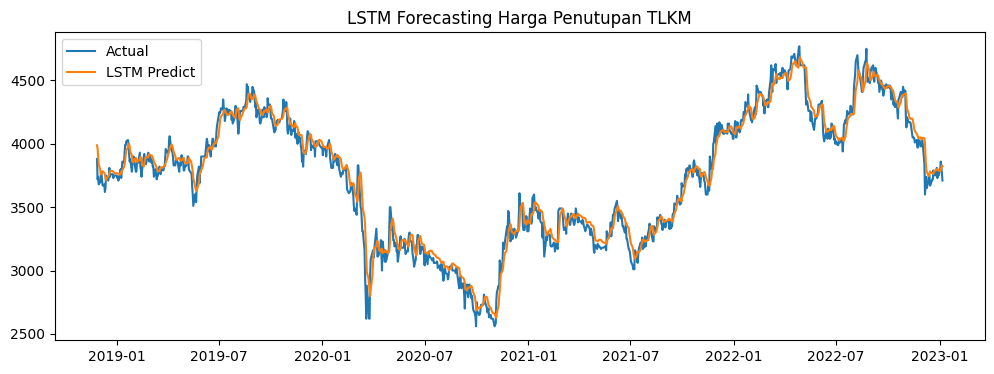

In [64]:
plt.figure(figsize=(12,4))
plt.plot(test.index[-len(actual):], actual, label='Actual')
plt.plot(test.index[-len(lstm_pred):], lstm_pred, label='LSTM Predict')
plt.title("LSTM Forecasting Harga Penutupan TLKM")
plt.legend()
plt.show()


In [65]:
import pandas as pd

# Masukkan nilai evaluasi
results = {
    'Model': ['ARIMA', 'Prophet', 'LSTM'],
    'RMSE': [arima_rmse, prophet_rmse, lstm_rmse],
    'MAPE': [arima_mape, prophet_mape, lstm_mape]
}

comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values(by='RMSE', ascending=True).reset_index(drop=True)

print("=== Perbandingan Ketiga Model ===")
print(comparison_df)


=== Perbandingan Ketiga Model ===
     Model         RMSE      MAPE
0     LSTM    87.462715  0.018290
1    ARIMA   553.101180  0.122561
2  Prophet  1497.810337  0.394369


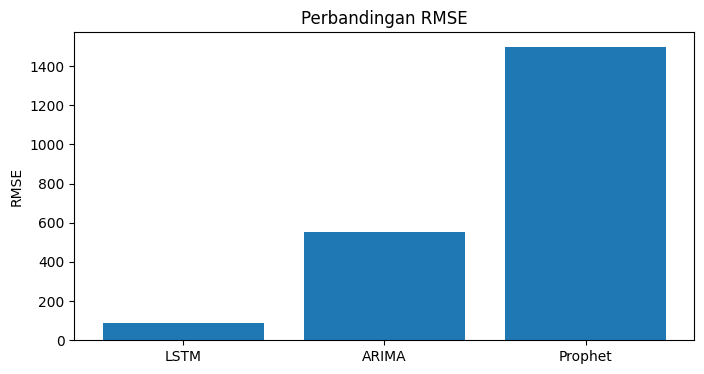

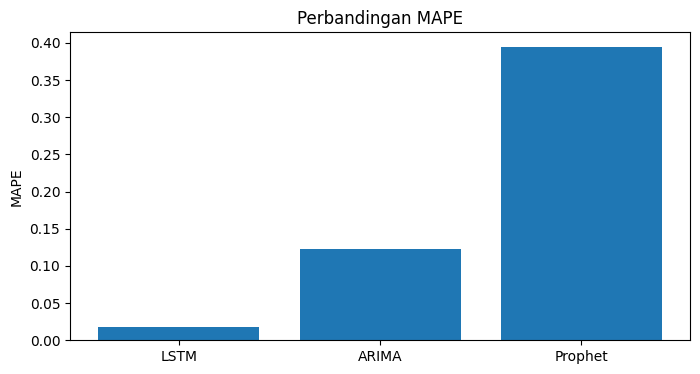

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.bar(comparison_df['Model'], comparison_df['RMSE'])
plt.title("Perbandingan RMSE")
plt.ylabel("RMSE")
plt.show()

plt.figure(figsize=(8,4))
plt.bar(comparison_df['Model'], comparison_df['MAPE'])
plt.title("Perbandingan MAPE")
plt.ylabel("MAPE")
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 314ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/s

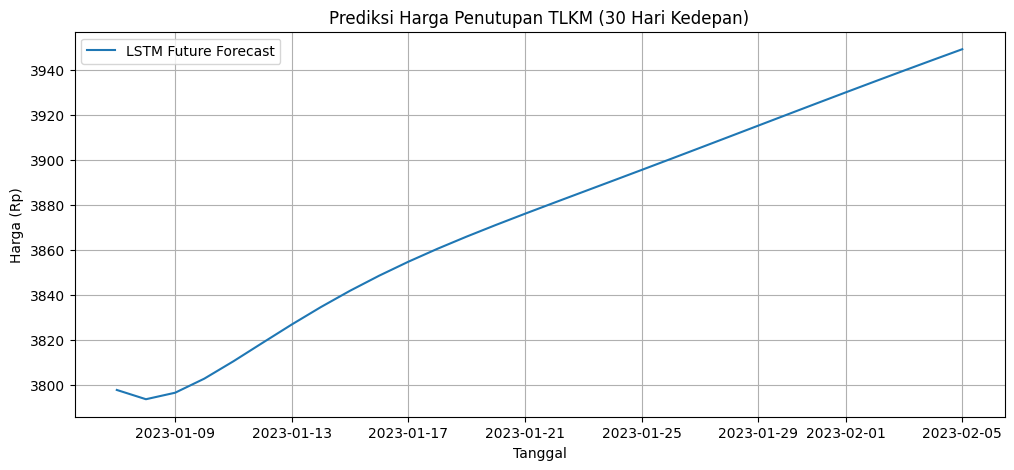

Prediksi Harga Penutupan TLKM 30 Hari Kedepan:
         date  predicted_close
0  2023-01-07      3797.697266
1  2023-01-08      3793.577637
2  2023-01-09      3796.460693
3  2023-01-10      3802.708740
4  2023-01-11      3810.433594
5  2023-01-12      3818.635254
6  2023-01-13      3826.762207
7  2023-01-14      3834.517822
8  2023-01-15      3841.761963
9  2023-01-16      3848.464600
10 2023-01-17      3854.657715
11 2023-01-18      3860.413818
12 2023-01-19      3865.823975
13 2023-01-20      3870.981934
14 2023-01-21      3875.970947
15 2023-01-22      3880.864258
16 2023-01-23      3885.714355
17 2023-01-24      3890.560059
18 2023-01-25      3895.423584
19 2023-01-26      3900.313721
20 2023-01-27      3905.229980
21 2023-01-28      3910.166016
22 2023-01-29      3915.110840
23 2023-01-30      3920.051758
24 2023-01-31      3924.977295
25 2023-02-01      3929.876221
26 2023-02-02      3934.739746
27 2023-02-03      3939.560791
28 2023-02-04      3944.334473
29 2023-02-05      3949

In [67]:
future_days = 30   # prediksi 30 hari ke depan

last_sequence = scaled_data[-60:]
future_predictions = []

current_seq = last_sequence.reshape(1, 60, 1)

for _ in range(future_days):
    future_pred_scaled = lstm_model.predict(current_seq)[0][0]

    # simpan hasil prediksi
    future_predictions.append(future_pred_scaled)

    # update sequence (geser + tambahkan prediksi)
    current_seq = np.append(current_seq[:, 1:, :], [[[future_pred_scaled]]], axis=1)

# balikkan ke scale asli
future_predictions_actual = scaler.inverse_transform(
    np.array(future_predictions).reshape(-1,1)
)

# Buat index tanggal ke depan
last_date = df['timestamp'].iloc[-1]
future_dates = pd.date_range(start=last_date, periods=future_days+1, freq='D')[1:]

# Plot hasil prediksi
plt.figure(figsize=(12,5))
plt.plot(future_dates, future_predictions_actual, label="LSTM Future Forecast")
plt.title("Prediksi Harga Penutupan TLKM (30 Hari Kedepan)")
plt.xlabel("Tanggal")
plt.ylabel("Harga (Rp)")
plt.legend()
plt.grid(True)
plt.show()

future_pred_df = pd.DataFrame({
    "date": future_dates,
    "predicted_close": future_predictions_actual.flatten()
})

print("Prediksi Harga Penutupan TLKM 30 Hari Kedepan:")
print(future_pred_df)


In [68]:
# Simpan model dan scaler
lstm_model.save("lstm_tlkm.h5")

import joblib
joblib.dump(scaler, "scaler.pkl")


['scaler.pkl']